# Gaussian beams, modes and the Gouy phase

The analytic beams in `pyoptics.beams` (Gauss-Laguerre and Gauss-Hermite) are
exact solutions of the paraxial wave equation. This notebook visualizes them and
compares them with numerical propagation (`pyoptics.propagators`). The highlight
is the **Gouy phase**, which can be seen directly in rotating mode superpositions.

**Convention:** $\exp(i(kz - \omega t))$. A beam travelling in $+z$ carries the
phase $e^{+ikz}$, behind the waist the wavefront is diverging ($R(z) > 0$), and the
Gouy phase enters as $e^{-i(N+1)\arctan(z/z_R)}$, with the mode order
$N = 2p + |l|$ (LG) or $N = l + m$ (HG).

Lengths in µm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb

from pyoptics import propagators as prop
from pyoptics.beams import gauss_laguerre, gauss_hermite
from pyoptics.masks import thin_lens
from pyoptics.utils import grid1d, grid2d, wavenumber

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 0.5
k = wavenumber(wl)

def complex_to_rgb(U, gamma=0.7):
    """Hue = phase, brightness = amplitude."""
    A = np.abs(U)/np.abs(U).max()
    H = (np.angle(U) + np.pi)/(2*np.pi)
    return hsv_to_rgb(np.dstack([H, np.ones_like(H), A**gamma]))

## 1. The fundamental mode: beam radius, radius of curvature, Gouy phase

A Gaussian beam with waist radius $w_0$ has the Rayleigh length
$z_R = \pi w_0^2/\lambda$ and

$$w(z) = w_0\sqrt{1 + (z/z_R)^2}, \qquad R(z) = z\,\big(1 + (z_R/z)^2\big), \qquad
  \psi(z) = \arctan(z/z_R).$$

With a small waist ($w_0 = 2\lambda$), wavefronts and beam shape fit into one
picture. Shown is the real part of the field (including the carrier $e^{ikz}$),
i.e. a snapshot of the wave.

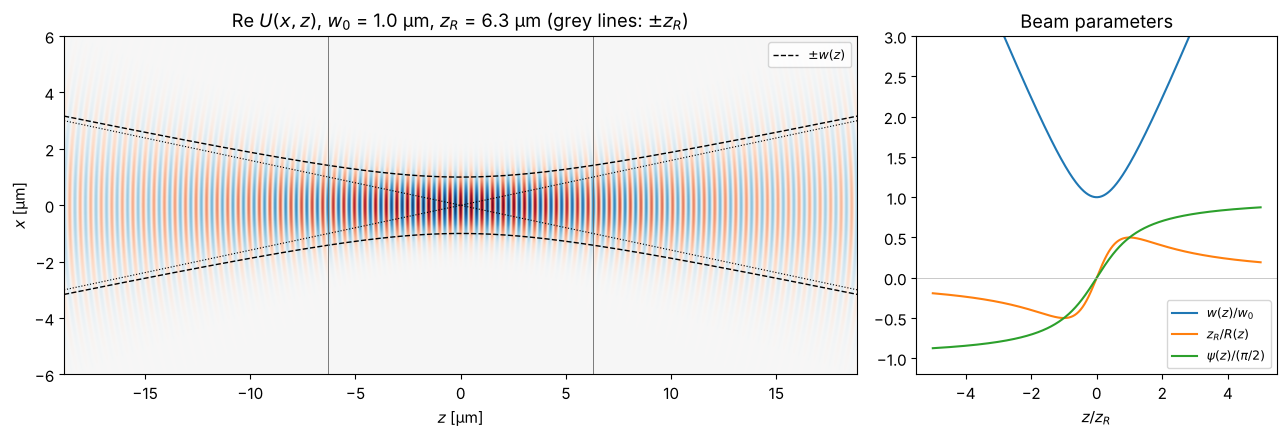

In [2]:
w0 = 1.0
z_R = np.pi*w0**2/wl
x = np.linspace(-6, 6, 401)
y0 = np.array([0.0])
z_vals = np.linspace(-3*z_R, 3*z_R, 1201)
field_xz = np.array([gauss_laguerre(0, 0, x, y0, z, w0, z_R, wl)[0] for z in z_vals])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
ext = (z_vals[0], z_vals[-1], x[0], x[-1])
axes[0].imshow(np.real(field_xz).T, extent=ext, aspect="auto", cmap="RdBu_r", interpolation="bilinear")
wz = w0*np.sqrt(1 + (z_vals/z_R)**2)
axes[0].plot(z_vals, wz, "k--", lw=1); axes[0].plot(z_vals, -wz, "k--", lw=1, label="$\\pm w(z)$")
axes[0].plot(z_vals, z_vals*wl/(np.pi*w0), "k:", lw=0.8); axes[0].plot(z_vals, -z_vals*wl/(np.pi*w0), "k:", lw=0.8)
for zz in (-z_R, z_R):
    axes[0].axvline(zz, color="0.4", lw=0.6)
axes[0].set_xlabel("$z$ [µm]"); axes[0].set_ylabel("$x$ [µm]")
axes[0].set_title(f"Re $U(x, z)$, $w_0$ = {w0} µm, $z_R$ = {z_R:.1f} µm (grey lines: $\\pm z_R$)")
axes[0].legend(loc="upper right", fontsize=9)

zz = np.linspace(-5*z_R, 5*z_R, 500)
axes[1].plot(zz/z_R, w0*np.sqrt(1 + (zz/z_R)**2)/w0, label="$w(z)/w_0$")
with np.errstate(divide="ignore"):
    axes[1].plot(zz/z_R, z_R/(zz*(1 + (z_R/zz)**2)), label="$z_R / R(z)$")
axes[1].plot(zz/z_R, np.arctan(zz/z_R)/(np.pi/2), label="$\\psi(z) / (\\pi/2)$")
axes[1].axhline(0, color="0.7", lw=0.5)
axes[1].set_xlabel("$z / z_R$"); axes[1].legend(fontsize=9); axes[1].set_ylim(-1.2, 3)
axes[1].set_title("Beam parameters")
fig.tight_layout()

One sees the flat wavefront at the waist, the maximum curvature at $z = \pm z_R$
and the spherical waves in the far field (dotted: divergence angle
$\theta = \lambda/(\pi w_0)$). Counting the wave crests on the axis, half a
wavelength is missing between $-\infty$ and $+\infty$: that is the Gouy phase $\pi$.

## 2. Analytic vs. numerical propagation

We take the field at the waist, propagate it with the exact Rayleigh-Sommerfeld
propagator and compare with `gauss_laguerre()` at $z$. For $w_0 = 10\lambda$ the
beam is well paraxial and both agree, including the phase.

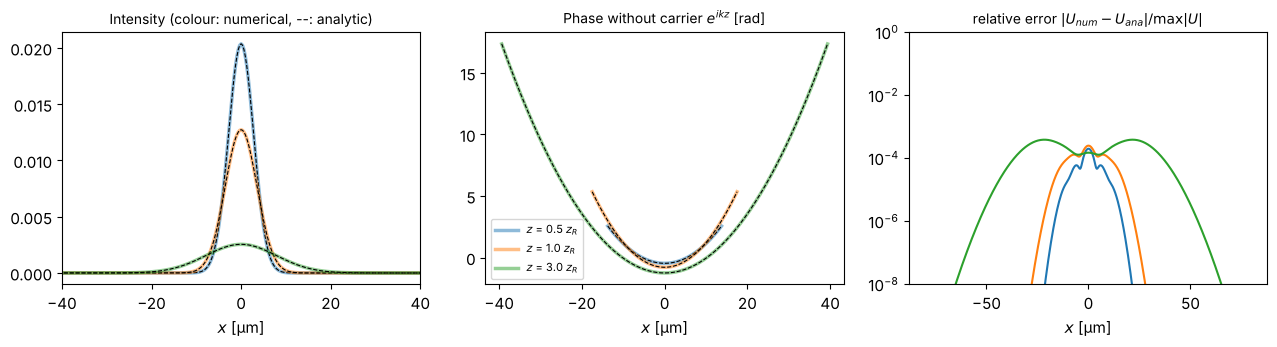

In [3]:
w0 = 5.0
z_R = np.pi*w0**2/wl
L, N = 160.0, 512
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
U0 = gauss_laguerre(0, 0, x, y, 0.0, w0, z_R, wl)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for z, c in zip((0.5*z_R, z_R, 3*z_R), ("C0", "C1", "C2")):
    U_num, _, _ = prop.propagate_padded(prop.rayleigh_sommerfeld_I_TF, U0, x, y, z, wl)
    U_ana = gauss_laguerre(0, 0, x, y, z, w0, z_R, wl)
    lab = f"$z$ = {z/z_R:.1f} $z_R$"
    axes[0].plot(x, np.abs(U_num[N//2])**2, c, lw=2.5, alpha=0.5)
    axes[0].plot(x, np.abs(U_ana[N//2])**2, "k--", lw=0.8)
    sel = np.abs(x) < 2.5*w0*np.sqrt(1 + (z/z_R)**2)
    for U, style in ((U_num, dict(color=c, lw=2.5, alpha=0.5, label=lab)), (U_ana, dict(color="k", ls="--", lw=0.8))):
        ph = np.angle(U[N//2]*np.exp(-1j*k*z))
        # unwrap starting from the centre so that the on-axis value stays in (-pi, pi]:
        ph_unwrapped = np.unwrap(ph[sel])
        ph_unwrapped -= ph_unwrapped[len(ph_unwrapped)//2] - ph[N//2]
        axes[1].plot(x[sel], ph_unwrapped, **style)
    axes[2].semilogy(x, np.abs(U_num[N//2] - U_ana[N//2])/np.abs(U_ana).max(), c, label=lab)
axes[0].set_xlim(-40, 40); axes[0].set_title("Intensity (colour: numerical, --: analytic)", fontsize=10)
axes[1].set_title("Phase without carrier $e^{ikz}$ [rad]", fontsize=10); axes[1].legend(fontsize=8)
axes[2].set_title("relative error $|U_{num} - U_{ana}| / \\max|U|$", fontsize=10); axes[2].set_ylim(1e-8, 1)
for ax in axes:
    ax.set_xlabel("$x$ [µm]")
fig.tight_layout()

The phase is an upward-opening parabola ($+k r^2/2R$ with $R>0$, diverging) on a
pedestal: the on-axis value is $-\psi(z)$, the Gouy phase ($-\pi/4$ at $z = z_R$).

## 3. The Gouy phase of higher modes, measured numerically

A mode of order $N$ picks up the Gouy phase $(N+1)\arctan(z/z_R)$. We propagate
HG modes numerically and measure the phase relative to the plane wave by
projecting the propagated field onto the analytic mode at $z$ (without Gouy phase).

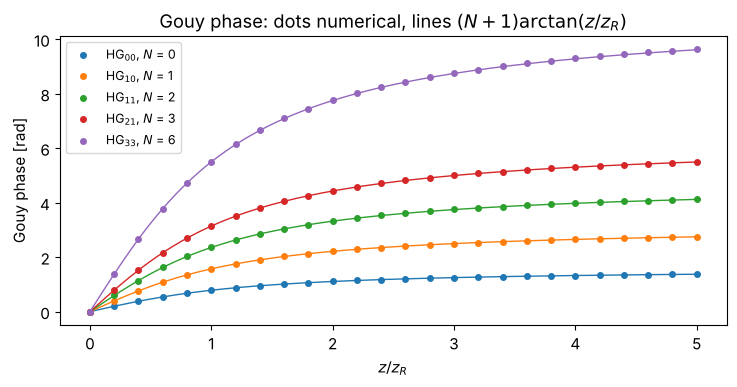

In [4]:
z_scan = np.linspace(0, 5*z_R, 26)
fig, ax = plt.subplots(figsize=(7.5, 4))
for (l, m), c in zip(((0, 0), (1, 0), (1, 1), (2, 1), (3, 3)), ("C0", "C1", "C2", "C3", "C4")):
    U0 = gauss_hermite(l, m, x, y, 0.0, w0, z_R, wl)
    gouy = []
    for z in z_scan:
        U_num, _, _ = prop.propagate_padded(prop.rayleigh_sommerfeld_I_TF, U0, x, y, z, wl)
        Nmode = l + m
        # analytic mode at z, with the Gouy phase taken out:
        ref = gauss_hermite(l, m, x, y, z, w0, z_R, wl)*np.exp(1j*(Nmode + 1)*np.arctan(z/z_R))*np.exp(-1j*k*z)
        overlap = np.sum(np.conj(ref)*U_num*np.exp(-1j*k*z))
        gouy.append(-np.angle(overlap))
    gouy = np.unwrap(gouy)
    zz = np.linspace(0, 5*z_R, 200)
    ax.plot(zz/z_R, (l + m + 1)*np.arctan(zz/z_R), c, lw=1)
    ax.plot(z_scan/z_R, gouy, "o", color=c, ms=4, label=f"HG$_{{{l}{m}}}$, $N$ = {l+m}")
ax.set_xlabel("$z / z_R$"); ax.set_ylabel("Gouy phase [rad]")
ax.set_title("Gouy phase: dots numerical, lines $(N+1)\\arctan(z/z_R)$")
ax.legend(fontsize=9)
fig.tight_layout()

## 4. Mode gallery

**Hermite-Gauss modes** HG$_{lm}$ have $l$ zeros in $x$ and $m$ in $y$;
**Laguerre-Gauss modes** LG$_{pl}$ have $p$ dark rings and a helical phase
$e^{il\varphi}$. For $l > 0$, every photon carries the orbital angular momentum
$+l\hbar$. In the LG images, hue encodes the phase and brightness the amplitude:
for $l = \pm 1$ the colour wheel goes around the beam axis once, for $l = \pm 2$
twice, with the opposite sense of rotation for negative $l$.

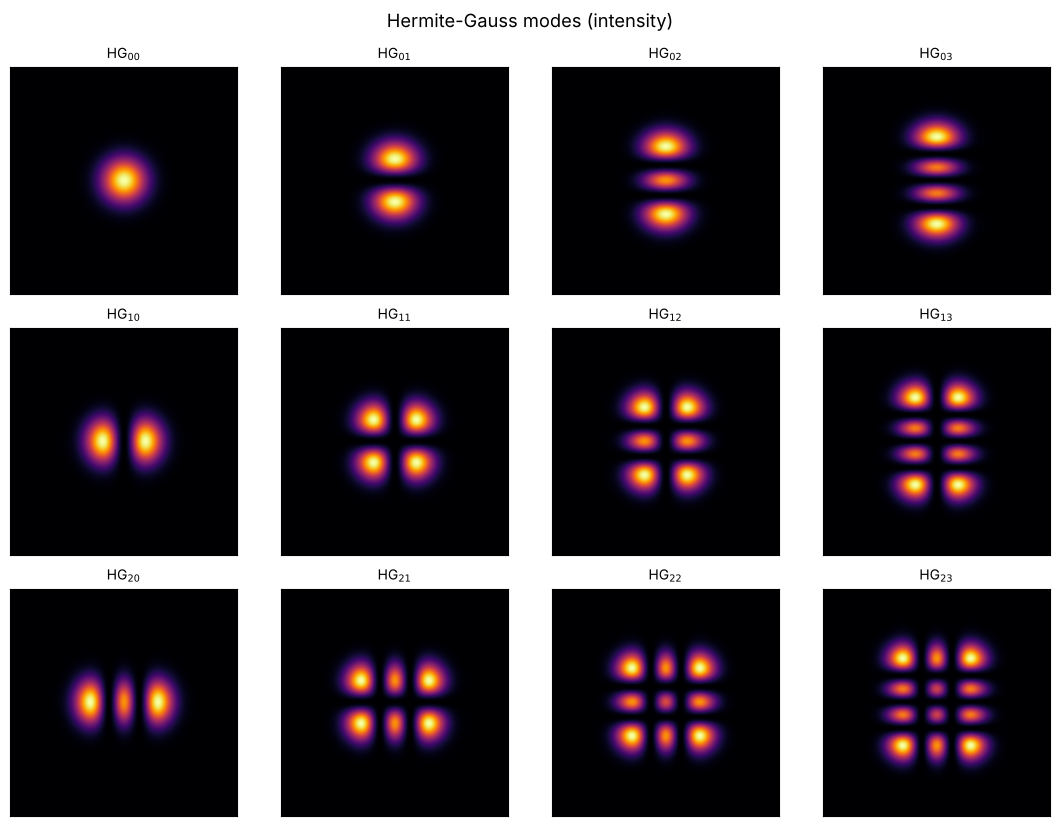

In [5]:
Lg, Ng = 30.0, 256
xg, yg, _, _ = grid2d(-Lg/2, Lg/2, -Lg/2, Lg/2, Ng)
w0g = 4.0
z_Rg = np.pi*w0g**2/wl

fig, axes = plt.subplots(3, 4, figsize=(11, 8.4))
for l in range(3):
    for m in range(4):
        U = gauss_hermite(l, m, xg, yg, 0.0, w0g, z_Rg, wl)
        axes[l, m].imshow(np.abs(U)**2, extent=(xg[0], xg[-1], yg[0], yg[-1]), cmap="inferno")
        axes[l, m].set_title(f"HG$_{{{l}{m}}}$", fontsize=10)
        axes[l, m].set_xticks([]); axes[l, m].set_yticks([])
fig.suptitle("Hermite-Gauss modes (intensity)")
fig.tight_layout()

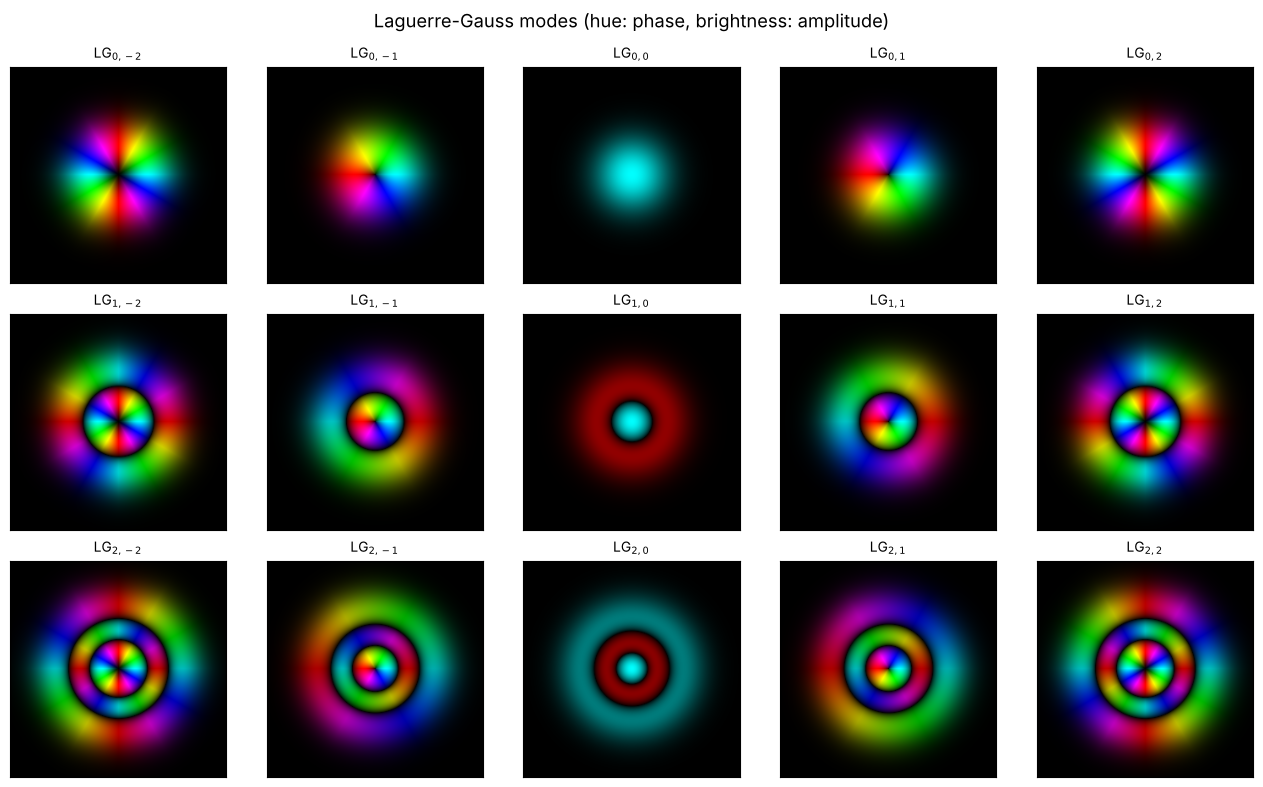

In [6]:
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for p in range(3):
    for j, l in enumerate(range(-2, 3)):
        U = gauss_laguerre(p, l, xg, yg, 0.0, w0g, z_Rg, wl)
        axes[p, j].imshow(complex_to_rgb(U), extent=(xg[0], xg[-1], yg[0], yg[-1]))
        axes[p, j].set_title(f"LG$_{{{p},{l}}}$", fontsize=10)
        axes[p, j].set_xticks([]); axes[p, j].set_yticks([])
fig.suptitle("Laguerre-Gauss modes (hue: phase, brightness: amplitude)")
fig.tight_layout()

## 5. The Gouy phase made visible: rotating beams

A superposition of modes of the **same** order $N$ keeps its shape on
propagation, because all of them pick up the same Gouy phase. An example:
HG$_{10}$ + $i$ HG$_{01}$ gives the doughnut mode LG$_{0,1}$.

For modes of **different** order, the relative phase changes with $z$. The
superposition LG$_{0,1}$ + LG$_{0,3}$ has the Gouy phases $2\psi$ and $4\psi$ and
the azimuthal phases $e^{i\varphi}$ and $e^{3i\varphi}$. The interference term is
$\propto \cos(2\varphi - 2\psi(z))$: two petals that rotate by the angle
$\psi(z) = \arctan(z/z_R)$. From $-\infty$ to $+\infty$ that is $180°$, half of it
within $\pm z_R$. We propagate numerically; the analytic expression only serves as
the starting field.

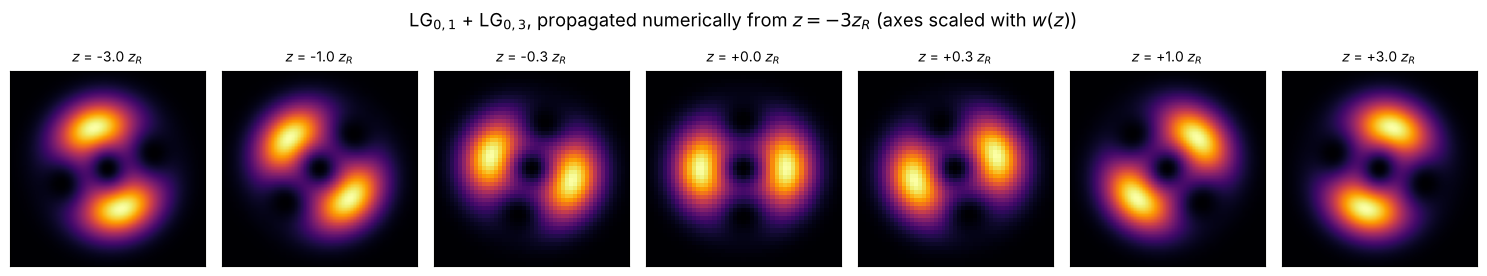

In [7]:
Lr, Nr = 120.0, 256
xr, yr, _, _ = grid2d(-Lr/2, Lr/2, -Lr/2, Lr/2, Nr)
w0r = 5.0
z_Rr = np.pi*w0r**2/wl
U0 = gauss_laguerre(0, 1, xr, yr, 0.0, w0r, z_Rr, wl) + gauss_laguerre(0, 3, xr, yr, 0.0, w0r, z_Rr, wl)
U_start = gauss_laguerre(0, 1, xr, yr, -3*z_Rr, w0r, z_Rr, wl) + gauss_laguerre(0, 3, xr, yr, -3*z_Rr, w0r, z_Rr, wl)

z_show = np.array([-3, -1, -0.3, 0, 0.3, 1, 3])*z_Rr
fig, axes = plt.subplots(1, len(z_show), figsize=(15, 2.9))
for ax, z in zip(axes, z_show):
    U, _, _ = prop.propagate_padded(prop.rayleigh_sommerfeld_I_TF, U_start, xr, yr, z + 3*z_Rr, wl)
    wz = w0r*np.sqrt(1 + (z/z_Rr)**2)
    ax.imshow(np.abs(U)**2, extent=(xr[0]/wz, xr[-1]/wz, yr[0]/wz, yr[-1]/wz), cmap="inferno")
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    ax.set_title(f"$z$ = {z/z_Rr:+.1f} $z_R$", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("LG$_{0,1}$ + LG$_{0,3}$, propagated numerically from $z = -3z_R$ (axes scaled with $w(z)$)")
fig.tight_layout()

## 6. Focusing with a thin lens

`masks.thin_lens()` returns the paraxial lens transmission $\exp(-ik r^2/2f)$,
which turns a plane wave into a wave converging at $z = f$. A collimated Gaussian
beam of radius $w$ is focused to the waist

$$w_f = \frac{\lambda f}{\pi w}.$$

We compute this with a cylindrical lens (in $x$ only) and the 1D helper from
notebook 01: two $y$ rows, transfer function propagator.

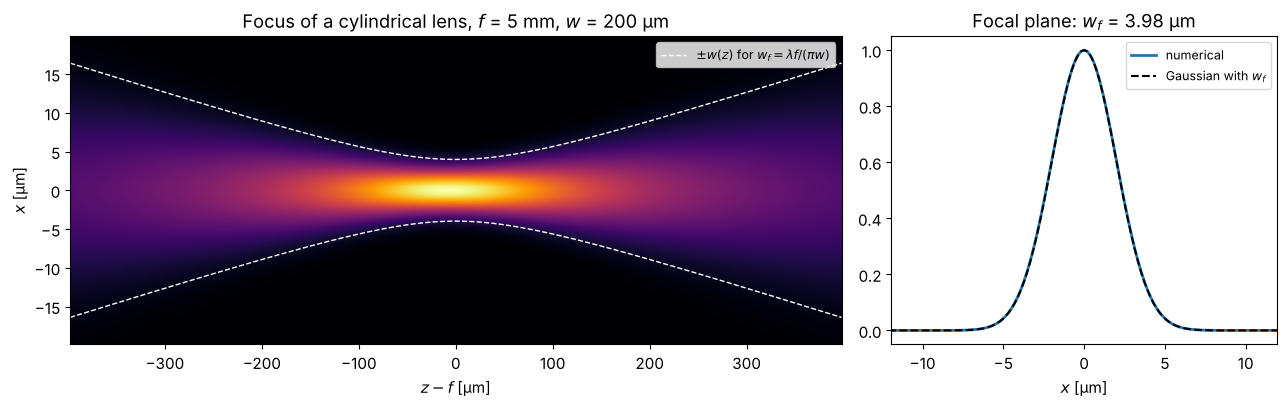

In [8]:
y_dummy = grid1d(-1, 1, 2)
def propagate_1d(propagator, u, x, z, wl, **kwargs):
    out, _, _ = propagator(np.tile(u, (2, 1)).astype(complex), x, y_dummy, z, wl, **kwargs)
    return out[0]

w_in, f = 200.0, 5000.0
Ll, Nl = 1600.0, 8192
xl = grid1d(-Ll/2, Ll/2, Nl)
u_lens = np.exp(-xl**2/w_in**2)*thin_lens(xl, np.array([0.0]), f, wl)[0]
w_f = wl*f/(np.pi*w_in)
z_Rf = np.pi*w_f**2/wl
z_vals = f + np.linspace(-4*z_Rf, 4*z_Rf, 241)
U_foc = np.array([propagate_1d(prop.rayleigh_sommerfeld_I_TF, u_lens, xl, z, wl) for z in z_vals])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2, 1]})
axes[0].imshow(np.abs(U_foc).T**2, extent=((z_vals[0] - f), (z_vals[-1] - f), xl[0], xl[-1]),
               aspect="auto", cmap="inferno", interpolation="bilinear")
dz = z_vals - f
axes[0].plot(dz, w_f*np.sqrt(1 + (dz/z_Rf)**2), "w--", lw=1, label="$\\pm w(z)$ for $w_f = \\lambda f/(\\pi w)$")
axes[0].plot(dz, -w_f*np.sqrt(1 + (dz/z_Rf)**2), "w--", lw=1)
axes[0].set_ylim(-5*w_f, 5*w_f); axes[0].legend(loc="upper right", fontsize=9)
axes[0].set_xlabel("$z - f$ [µm]"); axes[0].set_ylabel("$x$ [µm]")
axes[0].set_title(f"Focus of a cylindrical lens, $f$ = {f/1000:.0f} mm, $w$ = {w_in:.0f} µm")

i_f = np.argmin(np.abs(dz))
I_f = np.abs(U_foc[i_f])**2
axes[1].plot(xl, I_f/I_f.max(), lw=2, label="numerical")
axes[1].plot(xl, np.exp(-2*xl**2/w_f**2), "k--", label="Gaussian with $w_f$")
axes[1].set_xlim(-3*w_f, 3*w_f); axes[1].set_xlabel("$x$ [µm]"); axes[1].legend(fontsize=9)
axes[1].set_title(f"Focal plane: $w_f$ = {w_f:.2f} µm")
fig.tight_layout()

For lenses with a large Fresnel number like this one, the focus lies practically
at $f$. For a small Fresnel number $N_F = w^2/(\lambda f)$, the intensity maximum
moves towards the lens (*focal shift*). With the tools shown here this is easy to
try, e.g. with $w = 20$ µm and $f = 5$ mm.